<a href="https://colab.research.google.com/github/sofiarehakova/chantoff-behavioral-analysis/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import io, re, zipfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
for z in Path(".").glob("*.zip"):
    zipfile.ZipFile(z).extractall(Path("data") / z.stem)

def load_export(file):
    text = file.read_text(encoding="utf-8-sig")
    header, _, data = text.partition('"Date","Time"')
    filters = [r.strip('"').split('","') for r in header.splitlines()
               if r.startswith('"') and not r.startswith(('"Project', '"Date range', '"Total'))]
    kind = "sessions" if not filters else (filters[0][0] if filters[0][1] == "Yes" else filters[0][1])
    df = pd.read_csv(io.StringIO('"Date","Time"' + data))
    df["id"] = df["Recording link"].str.extract(r"/player/[^/]+/([^/]+/[^/]+)/")[0]
    return kind, df

exports = [load_export(f) for f in Path("data").rglob("*.csv") if "__MACOSX" not in f.parts]
print(pd.Series([kind for kind, _ in exports]).value_counts())

Dead clicks                                        4
Quick backs                                        3
sessions                                           3
Rage clicks                                        2
Play                                               1
Book                                               1
Sign up                                            1
Login                                              1
Show more                                          1
Withdraw                                           1
Outbound click                                     1
Submit form                                        1
Any JS error                                       1
error invoking postmessage: java object is gone    1
Name: count, dtype: int64


In [7]:
SIGNALS = ["Dead clicks", "Rage clicks", "Quick backs", "Any JS error"]
GOALS = ["Sign up", "Login", "Play", "Withdraw"]
EVENTS = ["Book", "Submit form", "Show more", "Outbound click"]

#merge the session lists and remove duplicates
records = pd.concat([df for kind, df in exports if kind == "sessions"])
S = records.drop_duplicates("id")
print("Records:", len(records), "| after removing duplicates:", len(S))

#add sessions that appear only in the filtered exports
filtered = pd.concat([df for kind, df in exports if kind != "sessions"])
S = pd.concat([S, filtered[~filtered["id"].isin(S["id"])].drop_duplicates("id")])
print("After adding missing sessions:", len(S))

#binary attributes
for name in SIGNALS + GOALS + EVENTS:
    ids = set().union(*[set(df["id"]) for kind, df in exports if kind == name])
    S[name] = S["id"].isin(ids).astype(int)

def to_seconds(duration):
    parts = [int(x) for x in duration.split(":")]
    return sum(p * 60 ** i for i, p in enumerate(reversed(parts)))

def page_type(url):
    path = re.sub(r"https?://[^/]+|\?.*|/en-gb", "", url)
    if path in ("", "/"):
        return "home page"
    if "/fangame" in path:
        return "Fangame"
    if "/sideline" in path or "/users/" in path:
        return "Sideline"
    if "/match/" in path:
        return "Match"
    if re.search(r"/(leagues?|teams?|players?|tournament)/", path):
        return "League, team and player"
    if "/shop" in path:
        return "Shop"
    return "Other"

S["duration_s"] = S["Session duration"].apply(to_seconds)
S["entry_page_type"] = S["Entry URL"].apply(page_type)
S["any_signal"] = S[SIGNALS].max(axis=1)
S["y"] = S[GOALS].max(axis=1)
print("Missing values:", S[["Device", "Entry URL", "Page count", "Session clicks"]].isna().sum().sum())

Records: 672 | after removing duplicates: 371
After adding missing sessions: 373
Missing values: 0


In [8]:
n = len(S)
pct = lambda x: f"{100 * x:.1f} %"
date = pd.to_datetime(S["Date"])
users = S["Clarity user ID"].value_counts()

print("Period:", date.min().date(), "–", date.max().date())
print("Sessions:", n, "| users:", len(users))
print("Sessions per user: median", users.median(), "| mean", round(users.mean(), 1), "| max", users.max())
print("Users with a single session:", pct((users == 1).mean()))
print("Sessions of the 4 most active users:", pct(users.head(4).sum() / n))
print(S["Device"].value_counts(), "\n")
print(S["Country"].value_counts().head(3), "\n")

print("TABLE 2")
print(S[["Page count", "Session clicks", "duration_s"]].describe().round(1).T, "\n")
print("Sessions without a click:", pct((S["Session clicks"] == 0).mean()))
print("Sessions with one page:", pct((S["Page count"] == 1).mean()))
print("Median duration of sessions without a click:", S.loc[S["Session clicks"] == 0, "duration_s"].median(), "s\n")

print("SIGNALS AND EVENTS (number of sessions)")
print(S[SIGNALS + ["any_signal"] + GOALS + ["y"] + EVENTS].sum().to_string())
print("Users with y = 1:", S.loc[S["y"] == 1, "Clarity user ID"].nunique())
print("Sessions with two goal actions:", (S[GOALS].sum(axis=1) == 2).sum())
print("Submit form together with Login or Sign up:",
      ((S["Submit form"] == 1) & (S[["Login", "Sign up"]].max(axis=1) == 1)).sum())
print("\nShare of signals by device:")
print(S.groupby("Device")[["Dead clicks", "Quick backs", "any_signal"]].mean().round(3), "\n")

ref = S["Referrer:"].astype(str)
print("Referrer with Cloudflare token:", pct(ref.str.contains("__cf_chl").mean()),
      "| empty:", pct(S["Referrer:"].isna().mean()),
      "| chantoff.com:", pct(ref.str.contains("chantoff.com").mean()), "\n")

print("TABLE 3")
print(S["entry_page_type"].value_counts())

Period: 2026-10-02 – 2026-11-16
Sessions: 373 | users: 86
Sessions per user: median 1.0 | mean 4.3 | max 91
Users with a single session: 81.4 %
Sessions of the 4 most active users: 66.0 %
Device
PC        334
Mobile     39
Name: count, dtype: int64 

Country
Slovakia          359
United States       5
Czech Republic      5
Name: count, dtype: int64 

TABLE 2
                count   mean    std  min    25%    50%     75%     max
Page count      373.0    3.5    7.2  1.0    1.0    1.0     3.0   108.0
Session clicks  373.0    6.0   16.2  0.0    0.0    0.0     5.0   223.0
duration_s      373.0  765.7  899.1  1.0  224.0  367.0  1100.0  5518.0 

Sessions without a click: 51.7 %
Sessions with one page: 61.9 %
Median duration of sessions without a click: 310.0 s

SIGNALS AND EVENTS (number of sessions)
Dead clicks       31
Rage clicks        2
Quick backs       84
Any JS error       2
any_signal        96
Sign up            1
Login             14
Play              15
Withdraw           8
y     

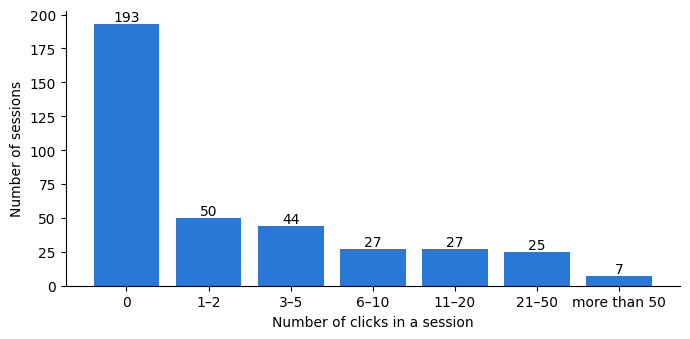

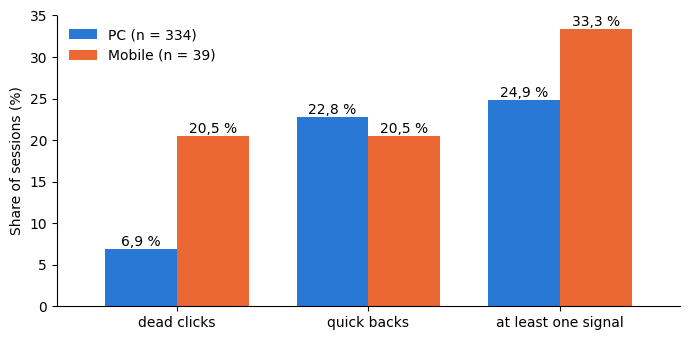

In [9]:
#distribution of clicks per session
groups = pd.cut(S["Session clicks"], [-1, 0, 2, 5, 10, 20, 50, float("inf")],
                labels=["0", "1–2", "3–5", "6–10", "11–20", "21–50", "more than 50"])
counts = groups.value_counts(sort=False)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(counts.index.astype(str), counts.values, color="#2a78d6")
ax.bar_label(ax.containers[0])
ax.set_xlabel("Number of clicks in a session")
ax.set_ylabel("Number of sessions")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("figure1.png", dpi=200)

#share of sessions with a frustration signal by device
shares = S.groupby("Device")[["Dead clicks", "Quick backs", "any_signal"]].mean().T * 100
shares = shares[["PC", "Mobile"]]
shares.index = ["dead clicks", "quick backs", "at least one signal"]
shares.columns = [f"PC (n = {(S['Device'] == 'PC').sum()})",
                  f"Mobile (n = {(S['Device'] == 'Mobile').sum()})"]
ax = shares.plot.bar(figsize=(7, 3.5), color=["#2a78d6", "#eb6834"], rot=0, width=0.75)
for bars in ax.containers:
    ax.bar_label(bars, labels=[f"{v:.1f} %".replace(".", ",") for v in bars.datavalues])
ax.set_ylabel("Share of sessions (%)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.figure.tight_layout()
ax.figure.savefig("figure2.png", dpi=200)